In [1]:
from google.colab import drive
drive.mount("/content/drive")

%pip install -q ultralytics opencv-python-headless matplotlib pandas

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 6.6 MB/s eta 0:00:00


In [2]:
from pathlib import Path
import torch
import ultralytics

PROJECT_DIR = Path("/content/drive/MyDrive/deeplearning")
DATASET_DIR = PROJECT_DIR / "Dataset" / "Dataset_for_yolo"

MODEL_PATH = PROJECT_DIR / "models" / "yolov8m_best.pt"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "sam21_integration"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cpu"

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())
print("YOLO model:", MODEL_PATH)
print("Output directory:", OUTPUT_DIR)

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Trained model not found at {MODEL_PATH}. "
        "Complete Notebook 03 first."
    )

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cpu
Ultralytics: 8.4.175
Device: cpu
CUDA available: False
YOLO model: /content/drive/MyDrive/deeplearning/models/yolov8m_best.pt
Output directory: /content/drive/MyDrive/deeplearning/outputs/sam21_integration


In [3]:
%cd /content

!git clone https://github.com/facebookresearch/sam2.git
%cd /content/sam2

%pip install -q -e .

/content
Cloning into 'sam2'...
remote: Enumerating objects: 1107, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 1107 (delta 13), reused 7 (delta 7), pack-reused 1089 (from 2)
Receiving objects: 100% (1107/1107), 134.85 MiB | 14.90 MiB/s, done.
Resolving deltas: 100% (385/385), done.
Updating files: 100% (569/569), done.
/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 12.1 MB/s eta 0:00:00
  Building editable for SAM-2 (pyproject.toml) ... done


In [5]:
from pathlib import Path
import urllib.request

CHECKPOINT_DIR = PROJECT_DIR / "models" / "sam2"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

SAM_CHECKPOINT = CHECKPOINT_DIR / "sam2.1_hiera_small.pt"

CHECKPOINT_URL = (
    "https://dl.fbaipublicfiles.com/"
    "segment_anything_2/092824/sam2.1_hiera_small.pt"
)

if not SAM_CHECKPOINT.exists():
    print("Downloading SAM 2.1 Small checkpoint...")

    request = urllib.request.Request(
        CHECKPOINT_URL,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    temporary_path = SAM_CHECKPOINT.with_suffix(".download")

    try:
        with urllib.request.urlopen(request, timeout=60) as response:
            with open(temporary_path, "wb") as f:
                while True:
                    chunk = response.read(1024 * 1024)
                    if not chunk:
                        break
                    f.write(chunk)

        if temporary_path.stat().st_size < 1_000_000:
            raise RuntimeError(
                "Downloaded file is unexpectedly small."
            )

        temporary_path.replace(SAM_CHECKPOINT)

    except Exception:
        temporary_path.unlink(missing_ok=True)
        raise

print("Checkpoint:", SAM_CHECKPOINT)
print("Size (MB):", round(SAM_CHECKPOINT.stat().st_size / 1e6, 2))

Checkpoint: /content/drive/MyDrive/deeplearning/models/sam2/sam2.1_hiera_small.pt
Size (MB): 184.42


In [6]:
import sys
import numpy as np
import cv2
import matplotlib.pyplot as plt

from ultralytics import YOLO

sys.path.insert(0, "/content/sam2")

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

# Load your trained detector on CPU
yolo_model = YOLO(str(MODEL_PATH))

# Load the pretrained segmentation model on CPU
sam_model = build_sam2(
    "configs/sam2.1/sam2.1_hiera_s.yaml",
    str(SAM_CHECKPOINT),
    device="cpu",
)

sam_predictor = SAM2ImagePredictor(sam_model)

print("YOLOv8m loaded.")
print("SAM 2.1 Small loaded on CPU.")
print("Classes:", yolo_model.names)

YOLOv8m loaded.
SAM 2.1 Small loaded on CPU.
Classes: {0: 'bottle'}


Selected image: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/images/000001_jpg.rf.3f7ad8a726437bc9a87073dc1cc0a290.jpg


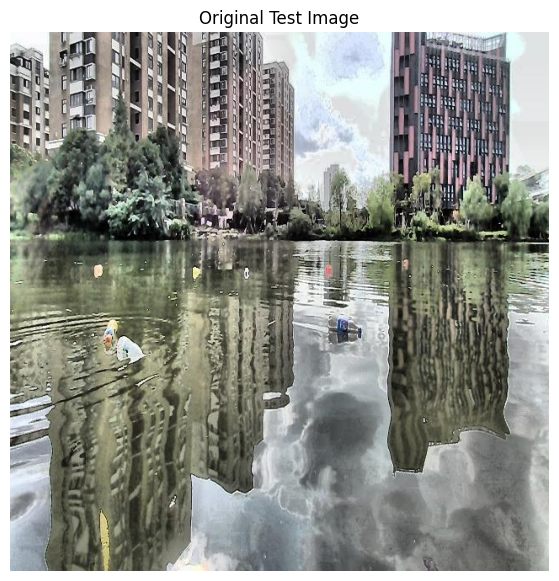

In [7]:
TEST_IMAGES = DATASET_DIR / "test" / "images"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

test_images = sorted(
    p for p in TEST_IMAGES.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

if not test_images:
    raise FileNotFoundError(f"No test images found in {TEST_IMAGES}")

IMAGE_PATH = test_images[0]

print("Selected image:", IMAGE_PATH)

image_bgr = cv2.imread(str(IMAGE_PATH))

if image_bgr is None:
    raise ValueError(f"Unable to read image: {IMAGE_PATH}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(image_rgb)
plt.title("Original Test Image")
plt.axis("off")
plt.show()

Detected bottles: 9
Detection 1: class=bottle, confidence=0.797, box=[126.80000305175781, 357.20001220703125, 160.60000610351562, 390.20001220703125]
Detection 2: class=bottle, confidence=0.774, box=[377.8999938964844, 336.29998779296875, 419.29998779296875, 360.8999938964844]
Detection 3: class=bottle, confidence=0.672, box=[111.5, 338.79998779296875, 123.5, 374.6000061035156]
Detection 4: class=bottle, confidence=0.658, box=[98.9000015258789, 274.1000061035156, 110.80000305175781, 287.29998779296875]
Detection 5: class=bottle, confidence=0.646, box=[111.4000015258789, 338.3999938964844, 128.3000030517578, 375.0]
Detection 6: class=bottle, confidence=0.632, box=[216.1999969482422, 277.0, 226.89999389648438, 290.8999938964844]
Detection 7: class=bottle, confidence=0.594, box=[466.3999938964844, 267.79998779296875, 473.29998779296875, 278.8999938964844]
Detection 8: class=bottle, confidence=0.550, box=[374.0, 274.79998779296875, 382.70001220703125, 287.70001220703125]
Detection 9: class

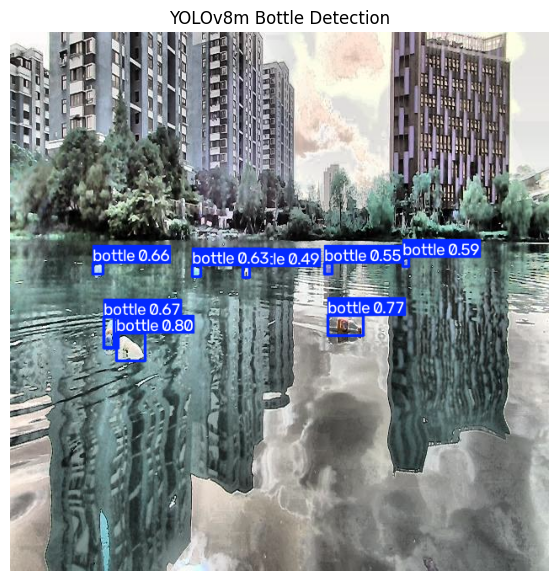

In [8]:
# Run detection on CPU
yolo_results = yolo_model.predict(
    source=image_rgb,
    imgsz=640,
    conf=0.25,
    device="cpu",
    verbose=False,
)

result = yolo_results[0]

boxes = result.boxes.xyxy.cpu().numpy()
confidences = result.boxes.conf.cpu().numpy()
class_ids = result.boxes.cls.cpu().numpy().astype(int)

print("Detected bottles:", len(boxes))

for i, (box, confidence, class_id) in enumerate(
    zip(boxes, confidences, class_ids), start=1
):
    print(
        f"Detection {i}: class={yolo_model.names[class_id]}, "
        f"confidence={confidence:.3f}, "
        f"box={np.round(box, 1).tolist()}"
    )

plt.figure(figsize=(10, 7))
plt.imshow(result.plot()[:, :, ::-1])
plt.title("YOLOv8m Bottle Detection")
plt.axis("off")
plt.show()

In [9]:
masks = []

if len(boxes) > 0:
    # SAM expects an RGB image
    sam_predictor.set_image(image_rgb)

    for i, box in enumerate(boxes):
        predicted_masks, scores, logits = sam_predictor.predict(
            box=box.astype(np.float32),
            multimask_output=False,
        )

        # One mask for each bounding box
        mask = predicted_masks[0].astype(bool)
        masks.append(mask)

        print(
            f"Detection {i + 1}: "
            f"SAM mask score={float(scores[0]):.4f}, "
            f"masked pixels={int(mask.sum())}"
        )

else:
    print("No bottles detected. No SAM masks generated.")

print("Masks generated:", len(masks))

Detection 1: SAM mask score=0.9486, masked pixels=750
Detection 2: SAM mask score=0.8650, masked pixels=722
Detection 3: SAM mask score=0.8382, masked pixels=371
Detection 4: SAM mask score=0.9241, masked pixels=153
Detection 5: SAM mask score=0.8710, masked pixels=456
Detection 6: SAM mask score=0.8921, masked pixels=132
Detection 7: SAM mask score=0.8557, masked pixels=67
Detection 8: SAM mask score=0.8704, masked pixels=106
Detection 9: SAM mask score=0.8757, masked pixels=82
Masks generated: 9


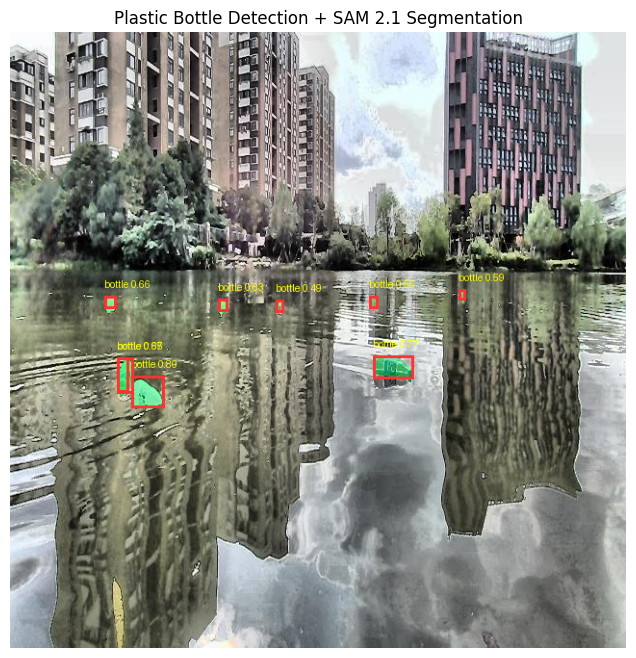

In [10]:
from PIL import Image, ImageDraw

overlay = image_rgb.copy()

# Create a separate display overlay for the masks
for mask in masks:
    color = np.array([0, 255, 100], dtype=np.uint8)

    overlay[mask] = (
        0.55 * overlay[mask] + 0.45 * color
    ).astype(np.uint8)

# Draw bounding boxes and confidence scores
display_image = Image.fromarray(overlay)
draw = ImageDraw.Draw(display_image)

for box, confidence, class_id in zip(boxes, confidences, class_ids):
    x1, y1, x2, y2 = map(int, box)

    draw.rectangle(
        [x1, y1, x2, y2],
        outline=(255, 50, 50),
        width=3,
    )

    label = (
        f"{yolo_model.names[class_id]} "
        f"{confidence:.2f}"
    )

    draw.text(
        (x1, max(0, y1 - 18)),
        label,
        fill=(255, 255, 0),
    )

plt.figure(figsize=(12, 8))
plt.imshow(display_image)
plt.title("Plastic Bottle Detection + SAM 2.1 Segmentation")
plt.axis("off")
plt.show()

In [11]:
import json

image_stem = IMAGE_PATH.stem

ANNOTATED_PATH = OUTPUT_DIR / f"{image_stem}_segmented.png"
MASK_DIR = OUTPUT_DIR / f"{image_stem}_masks"
MASK_DIR.mkdir(parents=True, exist_ok=True)

display_image.save(ANNOTATED_PATH)

combined_mask = np.zeros(image_rgb.shape[:2], dtype=np.uint8)

for i, mask in enumerate(masks, start=1):
    mask_image = (mask.astype(np.uint8) * 255)

    Image.fromarray(mask_image).save(
        MASK_DIR / f"bottle_{i}_mask.png"
    )

    combined_mask[mask] = 255

COMBINED_MASK_PATH = OUTPUT_DIR / f"{image_stem}_combined_mask.png"
Image.fromarray(combined_mask).save(COMBINED_MASK_PATH)

metadata = {
    "image": str(IMAGE_PATH),
    "detector": "YOLOv8m",
    "segmenter": "SAM 2.1 Small",
    "device": "cpu",
    "detections": [
        {
            "class": yolo_model.names[int(class_id)],
            "confidence": float(confidence),
            "bbox_xyxy": [float(v) for v in box],
            "mask_pixels": int(mask.sum()),
        }
        for box, confidence, class_id, mask in zip(
            boxes, confidences, class_ids, masks
        )
    ],
}

with open(OUTPUT_DIR / f"{image_stem}_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Annotated image:", ANNOTATED_PATH)
print("Individual masks:", MASK_DIR)
print("Combined mask:", COMBINED_MASK_PATH)

Annotated image: /content/drive/MyDrive/deeplearning/outputs/sam21_integration/000001_jpg.rf.3f7ad8a726437bc9a87073dc1cc0a290_segmented.png
Individual masks: /content/drive/MyDrive/deeplearning/outputs/sam21_integration/000001_jpg.rf.3f7ad8a726437bc9a87073dc1cc0a290_masks
Combined mask: /content/drive/MyDrive/deeplearning/outputs/sam21_integration/000001_jpg.rf.3f7ad8a726437bc9a87073dc1cc0a290_combined_mask.png
